# CALCE 数据集CS2电池的数据处理和异常cycle剔除

In [74]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
import openpyxl
from scipy import interpolate
from scipy.signal import savgol_filter

In [ ]:
#数据处理用hampel利用局部中值代替异常值，预处理Q，V，用于计算IC值
def hampel_filter(x, window_size=7, n_sigma=3):
    x = x.copy()

    k = 1.4826

    for i in range(len(x)):
        start = max(i - window_size, 0)
        end = min(i + window_size + 1, len(x))

        window = x[start:end]
        median = np.median(window)
        mad = k * np.median(np.abs(window - median))

        if mad == 0:
            continue
        if np.abs(x[i] - median) > n_sigma * mad:
            x[i] = median

    return x

In [76]:
class Loader:
    '''
    读取一个文件夹中的所有xlsx文件，并将它们合并成一个dataframe
    '''
    def __init__(self, folder='dataset/CS2_35'):
        self.folder = folder
        self.files = self._sort_file_by_time()
        self.df = self.merge_xlsx_file()
        print('--'*100)
        print('df.shape:', self.df.shape)
        print('columns:', self.df.columns)

    def _sort_file_by_time(self):
        '''
        每个CS2_xx文件夹中有多个文件，获取文件夹名字，并按时间排序
        :return:
        '''
        files = os.listdir(self.folder)
        files = sorted(files, key=lambda x: os.path.getmtime(os.path.join(self.folder, x)))

        print('该电池数据集一共包含{}个文件'.format(len(files)))
        return files

    def _get_sheet_names(self, path):
        '''
        获取xlsx文件中的sheet名称
        :param path: xlsx文件路径
        :return: list: sheet名称
        '''
        channel = 'Channel_1'  # xlsx文件中有Info、Channel_、Statistics_ 等sheet，只需要读取Channel_的sheet
        wb = openpyxl.load_workbook(path, read_only=True, keep_links=False)
        sheet_names = wb.sheetnames
        wb.close()

        needed_sheet_names = []
        for i in range(len(sheet_names)):
            this_sheet = wb[sheet_names[i]]
            if channel in this_sheet.title:
                print('--第' + str(i + 1) + '个sheet Name: ' + this_sheet.title)
                needed_sheet_names.append(this_sheet.title)
        return needed_sheet_names

    def read_one_xlsx(self, path):
        '''
        读取一个xlsx文件，返回一个dataframe
        :param path: xlsx文件路径
        :return:
        '''
        xlsx_path = os.path.join(self.folder, path)
        sheet_name = self._get_sheet_names(xlsx_path)
        if len(sheet_name) == 1:
            data = pd.read_excel(xlsx_path, sheet_name=sheet_name[0], usecols=[2, 3, 4, 5, 6, 7, 8, 9])
            print(f'--包含一张表：{sheet_name[0]}')
        elif len(sheet_name) == 2:
            df1 = pd.read_excel(xlsx_path, sheet_name=sheet_name[0], usecols=[2, 3, 4, 5, 6, 7, 8, 9])
            df2 = pd.read_excel(xlsx_path, sheet_name=sheet_name[1], usecols=[2, 3, 4, 5, 6, 7, 8, 9])
            data = pd.concat([df1, df2])
            data.index = range(data.shape[0])
            print(f'--包含两张张表：{sheet_name[0]}')
            print(f'    -------- {sheet_name[1]}')
        else:
            print('--None')
            return None
        return data

    def merge_xlsx_file(self):
        '''
        把所有xlsx合并成为一个dataframe
        :return:
        '''
        All_dfs = []
        for file in self.files:
            print(f'正在读取文件：{file}')
            df_i = self.read_one_xlsx(file)
            All_dfs.append(df_i)
        df = pd.concat(All_dfs, ignore_index=True)
        df['Date_Time'] = pd.to_datetime(df['Date_Time'])
        df.sort_values(by='Date_Time', inplace=True)
        return df

In [ ]:
class Battery:
    def __init__(self,path):
        parent_dir = os.path.dirname(path)
        battery_name = os.path.basename(path)
        # 判断是否存在hdf5文件,存在则直接读取；如果不存在，则读取Excel文件处理并保存为hdf5文件
        hdf5_path = os.path.join(#parent_dir + '/' +
                                    battery_name + '.hdf5')
        if os.path.exists(hdf5_path):
            self.df = pd.read_hdf(hdf5_path, key=battery_name)
        else:
            loader = Loader(path)
            self.df = loader.df

            self.df.to_hdf(hdf5_path, key=battery_name, mode='w')

        self.variable_name = ['Date_Time', 'Step_Time(s)', 'Step_Index', 'Cycle_Index', 'Current(A)',
       'Voltage(V)', 'Charge_Capacity(Ah)', 'Discharge_Capacity(Ah)']
        self.preprocess_df()
        self.cycle_index = np.unique(self.df['Cycle_Index'].values)
        self.cycle_life = len(self.cycle_index)

        print('-'*40,f' Battery {battery_name} ','-'*40)
        print('电池寿命：',self.cycle_life)
        print('data shape:',self.df.shape)
        print('变量名:',self.variable_name)
        print('-'*100)

    def preprocess_df(self):
        '''
        对数据进行预处理，重新计算Cycle_Index
        :return:
        '''
        # 重新计算Cycle_Index, 对原有的列进行累加得到信的Cycle_Index
        diff = self.df['Cycle_Index'].diff()
        reset_points = diff < 0
        new_index = self.df['Cycle_Index'].copy()

        # 初始化
        cumulative_offset = 0
        prev_index = 0

        for i in np.where(reset_points)[0]:
            # 当前段最大值（上一段的最大值）
            segment_max = self.df['Cycle_Index'][prev_index:i].max()
            cumulative_offset = segment_max
            new_index[i:] += cumulative_offset

            # 更新上一段起点
            prev_index = i

        self.df['Cycle_Index'] = new_index

    def _check(self,cycle=None,variable=None):
        '''
        检查输入的cycle和variable是否合法
        :param cycle: int: 循环次数
        :param variable: str: 变量名
        :return: bool: 是否合法
        '''
        if cycle is not None:
            if cycle not in self.df['Cycle_Index'].values:
                raise ValueError('cycle should be in [{},{}]'.format(int(self.df['Cycle_Index'].min()),int(self.df['Cycle_Index'].max())))
        if variable is not None:
            if variable not in self.variable_name:
                raise ValueError('variable should be in {}'.format(self.variable_name))
        return True

    def get_cycle(self,cycle):
        '''
        获取第cycle次循环的数据
        :param cycle: int: 循环次数
        :return: DataFrame
        '''
        self._check(cycle=cycle)
        cycle_df = self.df[self.df['Cycle_Index']==cycle]
        return cycle_df

    def get_value(self,cycle,variable):
        '''
        获取第cycle次循环的某个变量的值
        :param cycle: 循环次数
        :param variable: 变量名
        :return:
        '''
        self._check(cycle=cycle,variable=variable)
        cycle_df = self.get_cycle(cycle)
        return cycle_df[variable].values

    def get_charge_data(self,cycle):
        '''
        获取第cycle次循环的充电数据
        :param cycle:
        :return:
        '''
        self._check(cycle=cycle)
        cycle_df = self.get_cycle(cycle)
        # 充电数据的电流为正值
        charge_data = cycle_df[cycle_df['Current(A)']>0.01]
        return charge_data

    def get_discharge_data(self,cycle):
        '''
        获取第cycle次循环的放电数据
        :param cycle:
        :return:
        '''
        self._check(cycle=cycle)
        cycle_df = self.get_cycle(cycle)
        # 放电数据的电流为负值
        discharge_data = cycle_df[cycle_df['Current(A)']<-0.01]
        return discharge_data

    def get_CC_charge(self,cycle, voltage_range=None):
        '''
        获取第cycle次循环的恒流充电数据，可以指定电压范围
        :param cycle: 循环次数
        :param voltage_range: tuple或list或None: 电压范围，默认为None表示整个CC阶段; 其他形如[3.8,4.0]
        :return:
        '''
        self._check(cycle=cycle)
        charge_data = self.get_charge_data(cycle)
        # 恒流充电阶段，电压小于4.2V
        if voltage_range is None:
            CC_charge_data = charge_data[charge_data['Voltage(V)'] < 4.199]
        else:
            index = np.where((charge_data['Voltage(V)'] > voltage_range[0]) &
                              (charge_data['Voltage(V)'] < voltage_range[1]))[0]
            CC_charge_data = charge_data.iloc[index]
        return CC_charge_data

    def get_CV_charge(self,cycle, current_range=None):
        '''
        获取第cycle次循环的恒压充电数据，可以指定电流范围
        :param cycle: 循环次数
        :param current_range: tuple或list或None: 电流范围，默认为None表示整个CV阶段; 其他形如[1.0,0.1]
        :return:
        '''
        self._check(cycle=cycle)
        charge_data = self.get_charge_data(cycle)
        CV_charge_data = charge_data[charge_data['Voltage(V)'] > 4.199]
        if current_range is None:
            return CV_charge_data
        else:
            index = np.where((CV_charge_data['Current(A)'] > min(current_range)) &
                              (CV_charge_data['Current(A)'] < max(current_range)))[0]
            CV_charge_data = CV_charge_data.iloc[index]
            return CV_charge_data
        
    
    def get_IC_curve2(self,cycle,voltage_range=[4.0,4.1999]):
        '''
        计算增量容量曲线的非插值版本，公式为：dQ/dV,其中Q为容量，V为电压
        :return:
        '''
        Q = self.get_CC_charge(cycle=cycle, voltage_range=voltage_range)['Charge_Capacity(Ah)'].values
        V = self.get_CC_charge(cycle=cycle, voltage_range=voltage_range)['Voltage(V)'].values

        Q = np.array(Q)
        V = np.array(V)

        Q = hampel_filter(Q, window_size=7, n_sigma=3)
        V = hampel_filter(V, window_size=7, n_sigma=3)
        Q = savgol_filter(Q, window_length=11, polyorder=2)
        V = savgol_filter(V, window_length=11, polyorder=2)

        dQ = np.diff(Q)
        dV = np.diff(V)

        V_mid = (V[1:] + V[:-1]) / 2
        eps = 1e-4
        mask = (dV > eps) & (dQ > 0)

        IC = dQ[mask] / dV[mask]
        V_IC = V_mid[mask]
        return IC,V_IC

def plot_one_cycle(cycle_df):
    '''
    画一个cycle的曲线
    :param cycle_df:
    :return:
    '''
    fig,ax = plt.subplots(2,4,figsize=(12,6))
    for i in range(8):
        row = i // 4
        col = i % 4
        colname  = cycle_df.columns[i]
        ax[row,col].scatter(cycle_df.index,cycle_df[colname])
        ax[row,col].set_title(colname)
    plt.tight_layout()
    plt.show()

### 初始配置

该电池数据集一共包含28个文件
正在读取文件：CS2_38_8_17_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_8_18_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_8_19_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_8_30_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_9_7_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_9_14_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_9_21_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_9_28_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_10_04_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_10_05_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_10_14_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_10_21_10.xlsx
--第2个sheet Name: Channel_1-011
--包含一张表：Channel_1-011
正在读取文件：CS2_38_10_28_1

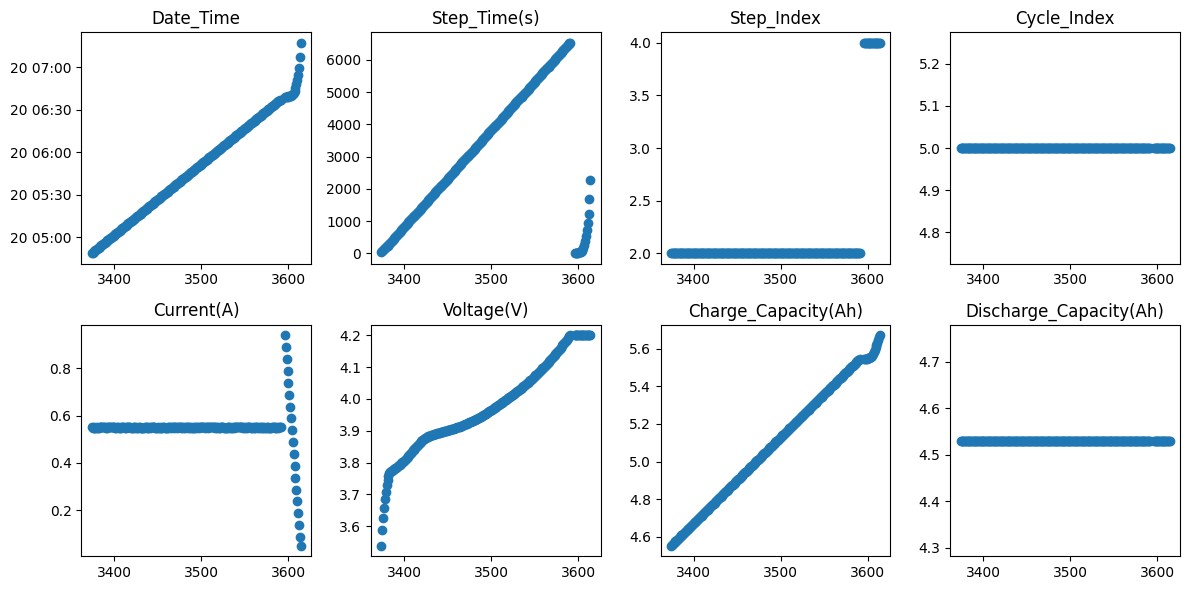

In [143]:
folder = 'dataset/CS2_38'
battery = Battery(folder)
cycle_df = battery.get_charge_data(5)
plot_one_cycle(cycle_df)
start_cycle = 2 # 设置起始循环，因为cycle1会出现异常数值
error_cycles = [] # 用以储存异常循环的cycle数

Cycle 94 skipped due to insufficient voltage data points (0 points).
Cycle 269 skipped due to insufficient voltage data points (0 points).
Cycle 445 skipped due to insufficient voltage data points (6 points).
Cycle 612 skipped due to insufficient voltage data points (0 points).
Cycle 788 skipped due to insufficient voltage data points (2 points).
Cycle 979 skipped due to insufficient voltage data points (36 points).
Cycle 980 skipped due to insufficient voltage data points (36 points).


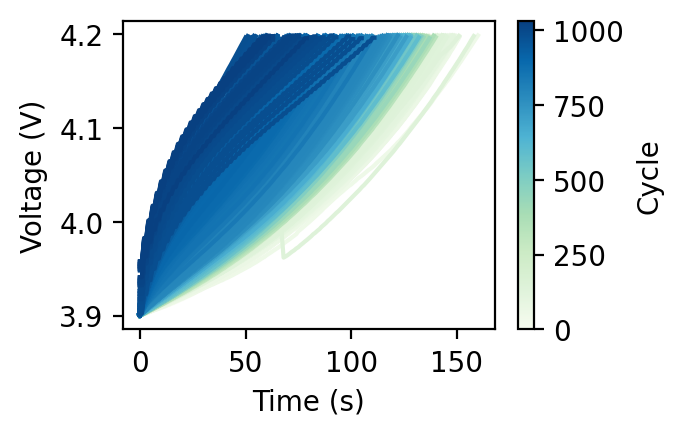

In [144]:
fig, ax = plt.subplots(figsize=(3, 2),dpi=200)
cm = plt.cm.GnBu(np.linspace(0,1,battery.cycle_life))
sm = plt.cm.ScalarMappable(cmap='GnBu',norm=plt.Normalize(vmin=0,vmax=battery.cycle_life))
for cycle in range(start_cycle,battery.cycle_life+1,1): # 每隔5个cycle画一次
    voltage = battery.get_CC_charge(cycle=cycle, voltage_range=[3.9,4.199])['Voltage(V)'].values
    if len(voltage) < 40:  # 如果电压数据点少于40个，则跳过该循环,用以删除某些异常循环
        print(f'Cycle {cycle} skipped due to insufficient voltage data points ({len(voltage)} points).')
        error_cycles.append(cycle)
        continue
    plt.plot(voltage,color=cm[cycle-1])
plt.xlabel('Time (s)')
plt.ylabel('Voltage (V)')
cbar = plt.colorbar(sm,ax=ax,use_gridspec=True)
cbar.set_label('Cycle')
plt.show()

Cycle 94 skipped due to insufficient charge capacity data points (0 points).
Cycle 269 skipped due to insufficient charge capacity data points (0 points).
Cycle 445 skipped due to insufficient charge capacity data points (0 points).
Cycle 612 skipped due to insufficient charge capacity data points (0 points).
Cycle 788 skipped due to insufficient charge capacity data points (0 points).
Cycle 980 skipped due to insufficient charge capacity data points (16 points).


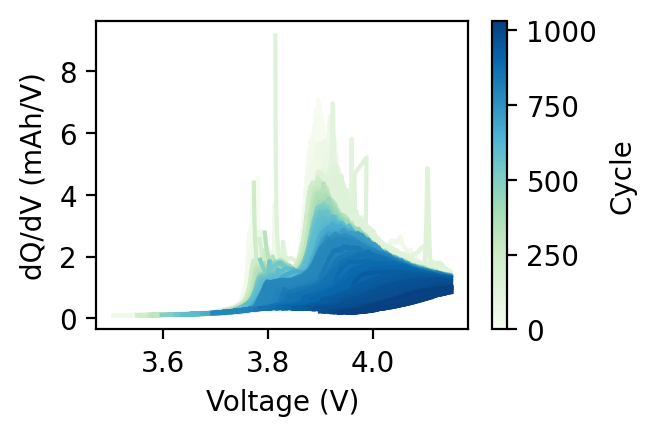

In [145]:
fig, ax = plt.subplots(figsize=(3, 2),dpi=200)
cm = plt.cm.GnBu(np.linspace(0,1,battery.cycle_life))
sm = plt.cm.ScalarMappable(cmap='GnBu',norm=plt.Normalize(vmin=0,vmax=battery.cycle_life))
for cycle in range(start_cycle,battery.cycle_life+1,1):
    len_Q = battery.get_CC_charge(cycle=cycle, voltage_range=[3.4,4.15])['Charge_Capacity(Ah)'].values.size
    if len_Q < 30:  # 如果电压数据点少于30个，则跳过该循环,用以删除某些异常循环
        error_cycles.append(cycle)
        print(f'Cycle {cycle} skipped due to insufficient charge capacity data points ({len_Q} points).')
        continue
    IC,V = battery.get_IC_curve2(cycle=cycle,voltage_range=[3.4,4.15])
    plt.plot(V,IC,color=cm[cycle-1])
plt.xlabel('Voltage (V)')
plt.ylabel('dQ/dV (mAh/V)')
cbar = plt.colorbar(sm,cax=None,use_gridspec=True,ax=ax)
cbar.set_label('Cycle')
plt.show()

Cycle 269 skipped due to abnormal capacity increase (24.131894489137196 - 0.9985901423605661 > 0.7).
Cycle 445 skipped due to abnormal capacity increase (15.330750117987812 - 0.96451242452261 > 0.7).
Cycle 612 skipped due to abnormal capacity increase (14.462451221444132 - 0.8965528676304402 > 0.7).
Cycle 980 skipped due to abnormal capacity increase (19.008857121911973 - 0.4124881129129605 > 0.7).
Abnormal cycles detected: [ 67  86  94 119 174 208 218 227 269 272 278 327 381 390 445 446 447 459
 470 494 584 594 602 612 659 683 693 715 758 759 760 783 788 803 833 892
 901 971 980]


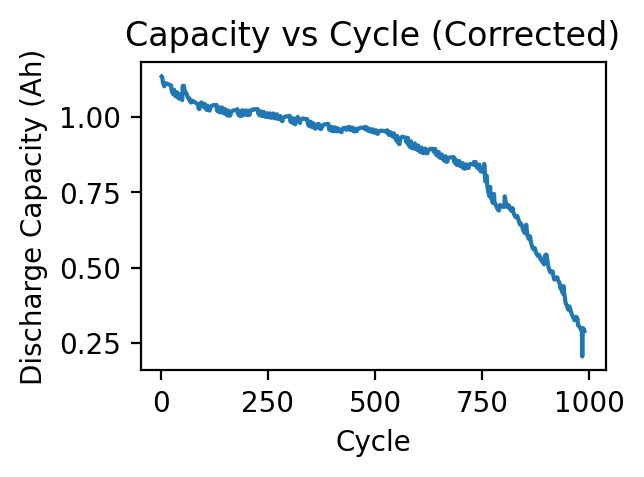

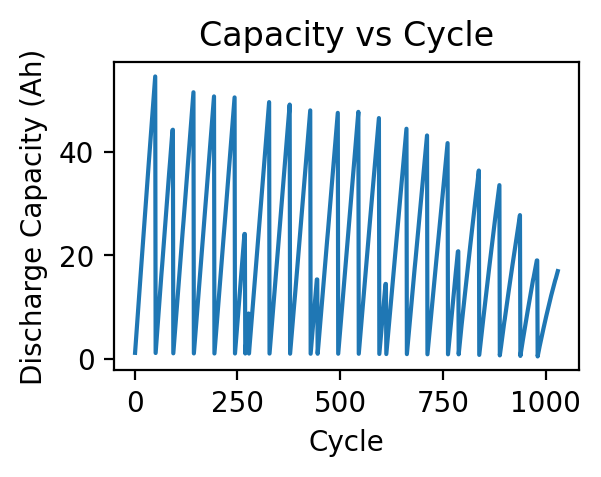

In [146]:
# SOH 的检查
# 约50个cycle一个xlsx,每个xlsx内的discharge capacity是累积的，直接plot会得到锯齿样的折线图
# 可通过cycle初始的discharge_capacity 变量来判断是否进入下一个xlsx，同一个xlsx内则可令cycle(x)-cycle(x-1)的discharge_capacity作为cycle(x)的discharge_capacity。
Capacity_list = []
first_capacity = battery.get_cycle(cycle=start_cycle)['Discharge_Capacity(Ah)'].values[-1] - battery.get_cycle(cycle=start_cycle-1)['Discharge_Capacity(Ah)'].values[-1]
Capacity_list.append(first_capacity)
for cycle in range(start_cycle,battery.cycle_life):
    Q_discharge0 = battery.get_cycle(cycle=cycle)['Discharge_Capacity(Ah)'].values
    Q_discharge1 = battery.get_cycle(cycle=cycle+1)['Discharge_Capacity(Ah)'].values
    if Q_discharge1[-1] > Q_discharge0[-1]:
        Capacity_list.append(Q_discharge1[-1]-Q_discharge0[-1])
    else:
        Capacity_list.append(Q_discharge1[-1])

# 检查一下error cycle，粗筛异常cycle
for i in range(len(Capacity_list)):
    if Capacity_list[i] - Capacity_list[0] > 0.7:
        error_cycles.append(i+start_cycle+1)
        print(f'Cycle {i+start_cycle+1} skipped due to abnormal capacity increase ({Capacity_list[i]} - {Capacity_list[i-1]} > 0.7).')

# 精细筛选突然向下跳动的cycle
capacity = np.array(Capacity_list)
threshold = 0.1
left_diff = np.abs(capacity[1:-1] - capacity[:-2])
right_diff = np.abs(capacity[1:-1] - capacity[2:])

abnormal = np.where(
    (left_diff > threshold) &
    (right_diff > threshold))[0] + 1
error_cycles.extend(abnormal + start_cycle + 1)
print(f'Abnormal cycles detected: {abnormal + start_cycle + 1}')

# 剔除一下error cycle        
Capacity_list_new = [Capacity_list[i] for i in range(len(Capacity_list)) if (i+start_cycle+1) not in error_cycles]

plt.figure(figsize=(3, 2),dpi=200)
plt.plot(range(start_cycle,len(Capacity_list_new)+start_cycle),Capacity_list_new)
plt.xlabel('Cycle')
plt.ylabel('Discharge Capacity (Ah)')
plt.title('Capacity vs Cycle (Corrected)')
plt.show()

step_time_list = []
for cycle in range(1,battery.cycle_life+1):
    cycle_df = battery.get_cycle(cycle)
    step_time = cycle_df['Discharge_Capacity(Ah)'].values
    step_time_list.append(step_time[-1] if len(step_time) > 0 else 0)

plt.figure(figsize=(3, 2),dpi=200)
plt.plot(range(1,battery.cycle_life+1),step_time_list)
plt.xlabel('Cycle')
plt.ylabel('Discharge Capacity (Ah)')
plt.title('Capacity vs Cycle')
plt.show()



In [147]:
error_cycles = list(set(error_cycles))  # 去重
error_cycles.sort()  # 排序
print(f'Error cycles: {error_cycles}')
num_cycles = battery.cycle_life - start_cycle - len(error_cycles)+1
print(f'Number of cycles analyzed: {num_cycles}')

Error cycles: [np.int64(67), np.int64(86), 94, np.int64(119), np.int64(174), np.int64(208), np.int64(218), np.int64(227), 269, np.int64(272), np.int64(278), np.int64(327), np.int64(381), np.int64(390), 445, np.int64(446), np.int64(447), np.int64(459), np.int64(470), np.int64(494), np.int64(584), np.int64(594), np.int64(602), 612, np.int64(659), np.int64(683), np.int64(693), np.int64(715), np.int64(758), np.int64(759), np.int64(760), np.int64(783), 788, np.int64(803), np.int64(833), np.int64(892), np.int64(901), np.int64(971), 979, 980]
Number of cycles analyzed: 988


### ！！后续提取特征，请剔除 error_cycles 中的循环